In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import TargetEncoder

Matplotlib is building the font cache; this may take a moment.


In [3]:
df = pd.read_csv("House Price Prediction Dataset.csv")

df.head(2)

,Id,Area,Bedrooms,Bathrooms,Floors,YearBuilt,Location,Condition,Garage,Price
0,1,1360,5,4,3,1970,Downtown,Excellent,No,149919
1,2,4272,5,4,3,1958,Downtown,Excellent,No,424998


In [23]:
df.columns

Index(['Id', 'Area', 'Bedrooms', 'Bathrooms', 'Floors', 'YearBuilt',
       'Location', 'Condition', 'Garage', 'Price', 'Garage_Yes'],
      dtype='str')

In [4]:
df['Garage_Yes']=pd.get_dummies(df['Garage'], drop_first=True)

df['Garage_Yes'] = df['Garage_Yes'].replace({
    False: 0,
    True: 1  
})

df.head(5)

,Id,Area,Bedrooms,Bathrooms,Floors,YearBuilt,Location,Condition,Garage,Price,Garage_Yes
0,1,1360,5,4,3,1970,Downtown,Excellent,No,149919,0
1,2,4272,5,4,3,1958,Downtown,Excellent,No,424998,0
2,3,3592,2,2,3,1938,Downtown,Good,No,266746,0
3,4,966,4,2,2,1902,Suburban,Fair,Yes,244020,1
4,5,4926,1,4,2,1975,Downtown,Fair,Yes,636056,1


In [5]:
df.corr(numeric_only=True)['Price'].sort_values(ascending=False)

Price        1.000000
Floors       0.055890
YearBuilt    0.004845
Area         0.001542
Bedrooms    -0.003471
Bathrooms   -0.015737
Id          -0.025643
Name: Price, dtype: float64

In [6]:
df.info()
df.isna().sum()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 11 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Id          2000 non-null   int64 
 1   Area        2000 non-null   int64 
 2   Bedrooms    2000 non-null   int64 
 3   Bathrooms   2000 non-null   int64 
 4   Floors      2000 non-null   int64 
 5   YearBuilt   2000 non-null   int64 
 6   Location    2000 non-null   str   
 7   Condition   2000 non-null   str   
 8   Garage      2000 non-null   str   
 9   Price       2000 non-null   int64 
 10  Garage_Yes  2000 non-null   object
dtypes: int64(7), object(1), str(3)
memory usage: 172.0+ KB


Id            0
Area          0
Bedrooms      0
Bathrooms     0
Floors        0
YearBuilt     0
Location      0
Condition     0
Garage        0
Price         0
Garage_Yes    0
dtype: int64

In [7]:
Q1 = df['Price'].quantile(0.25)
Q3 = df['Price'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Filter rows that are outliers
outliers = df[(df['Price'] < lower_bound) | (df['Price'] > upper_bound)]
outliers

,Id,Area,Bedrooms,Bathrooms,Floors,YearBuilt,Location,Condition,Garage,Price,Garage_Yes


In [8]:
df_train = df[df['YearBuilt'].between(1900,2000)]
df_eval = df[df['YearBuilt'].between(2001,2015)]
df_test = df[df['YearBuilt'].between(2016,2023)]

In [9]:
condition_counts = df_train['Condition'].value_counts()
df_train['coundtion_frequency'] = df_train['Condition'].map(condition_counts)
df_eval['coundtion_frequency'] = df_eval['Condition'].map(condition_counts)
df_test['coundtion_frequency'] = df_test['Condition'].map(condition_counts)

In [10]:
meanPrice = df_train.groupby('Location')['Price'].mean()
globalMean = df_train['Price'].mean()
#cols = ['Location']
#te = TargetEncoder(target_type='continuous', random_state=42)
#df_train['Location_encoded'] = te.fit_transform(df_train[cols],df_train['Price'])

df_train['Location_encoded'] = df_train['Location'].map(meanPrice)
df_eval['Location_encoded'] = df_eval['Location'].map(meanPrice).fillna(globalMean)
df_test['Location_encoded'] = df_test['Location'].map(meanPrice).fillna(globalMean)

In [12]:
df_train_processed = df_train.drop(columns=['Location','Condition','Garage','Id'])
df_eval_processed = df_eval.drop(columns=['Location','Condition','Garage','Id'])
df_test_processed = df_test.drop(columns=['Location','Condition','Garage','Id'])

In [13]:
x_train = df_train_processed.drop('Price',axis=1)
y_train = df_train_processed['Price']

x_eval = df_eval_processed.drop('Price',axis=1)
y_eval = df_eval_processed['Price']

x_test = df_test_processed.drop('Price',axis=1)
y_test = df_test_processed['Price']

In [14]:
from sklearn.preprocessing import PolynomialFeatures

poly_feat = PolynomialFeatures(degree=2,include_bias=False)
x_train_poly = poly_feat.fit_transform(x_train)
x_eval_poly = poly_feat.transform(x_eval)
x_test_poly = poly_feat.transform(x_test)

In [16]:
from sklearn.preprocessing import StandardScaler

sc = StandardScaler()
sc_x_train = sc.fit_transform(x_train_poly)
sc_x_eval = sc.transform(x_eval_poly)
sc_x_test = sc.transform(x_test_poly)

In [24]:
sc_x_train

array([[-1.08620503,  1.39484605,  1.3141973 , ...,  0.17807688,
         0.08311949, -0.22601933],
       [ 1.15165234,  1.39484605,  1.3141973 , ...,  0.17807688,
         0.08311949, -0.22601933],
       [ 0.62907575, -0.70650293, -0.50003331, ..., -1.6010024 ,
        -1.53194493, -0.22601933],
       ...,
       [-1.31521653,  1.39484605, -1.40714862, ..., -0.04376496,
        -0.00297076,  0.00919892],
       [ 0.99026839, -0.00605327, -1.40714862, ...,  0.17807688,
        -0.38907705, -1.24046086],
       [ 0.16567329,  1.39484605, -1.40714862, ...,  1.23352272,
         1.82299145,  1.58602411]], shape=(1620, 44))

In [17]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

lr_model = LinearRegression()
lr_model.fit(sc_x_train,y_train)
y_eval_pred = lr_model.predict(sc_x_eval)

r2 = r2_score(y_eval,y_eval_pred)
r2

0.0049187927010080346

In [18]:
from sklearn.linear_model import RidgeCV

ridge_model = RidgeCV(alphas=0.000000994)
ridge_model.fit(sc_x_train,y_train)
y_eval_ridge = ridge_model.predict(sc_x_eval)
r2 = r2_score(y_eval, y_eval_ridge)
r2

0.004918623232075925

In [20]:
from sklearn.linear_model import LassoCV

lasso_cv = LassoCV(eps=0.5,alphas=100,cv=5,max_iter=1000)
lasso_cv.fit(sc_x_train,y_train)
y_eval_lasso=lasso_cv.predict(sc_x_eval)
r2 = r2_score(y_eval,y_eval_lasso)
r2

-0.008695705363627182

<Axes: ylabel='Density'>

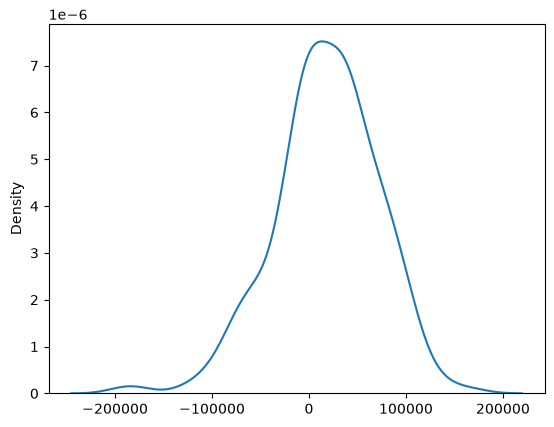

In [21]:
res = y_eval_lasso - y_eval_ridge
sns.kdeplot(res)